# 07. Score calibration, embedding space, latency and failure analysis

Part of Step 6's seven-notebook series: [01](01_dataset_and_chunking.ipynb) dataset/chunking, [02](02_experiment_a_chunking_strategy.ipynb) Experiment A, [03](03_experiment_b_search_mode.ipynb) Experiment B, [04](04_experiment_c_embedding_model.ipynb) Experiment C, [05](05_experiment_d_weights_and_rrf.ipynb) Experiment D, [06](06_experiment_e_rerank.ipynb) Experiment E, [07](07_calibration_and_analysis.ipynb) calibration/PCA/latency/failure analysis/conclusions. Each runs standalone against its own fresh ingest (via `_setup.py`); none depends on another's kernel state.

This notebook only runs the default pipeline (bge-small/section/hybrid, no
rerank) plus one `run_eval` call for the latency breakdown — it doesn't
reuse results from notebooks 02-06, since each notebook runs in its own
kernel. See those notebooks for the exact comparison numbers; this one's
conclusions are written in terms of them rather than reprinting them.


In [1]:
import _setup as s
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

W1031 11:14:57.987000 88462 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

## Score calibration

The distribution of `match_score` for not-relevant (grade 0), relevant
(grade 1) and highly-relevant (grade 2) candidates, across all 6 JDs —
a well-calibrated score should separate these bands.


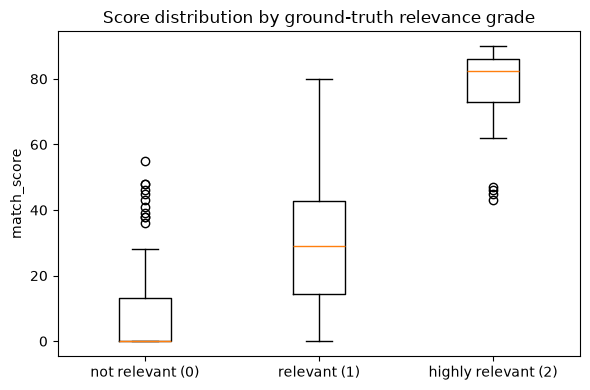

grade 0: n=144, mean=8.1, median=0.0
grade 1: n=42, mean=31.1, median=29.0
grade 2: n=30, mean=76.2, median=82.5


In [2]:
score_by_grade = {0: [], 1: [], 2: []}
for jd_path in s.jd_paths:
    jd_id = s.jd_id_for_path(jd_path)
    jd = s.parse_jd(jd_path.read_text())
    grades = {filename: grade for filename, grade in s.ground_truth[jd_id].items()}
    scored = s.score_all(jd)
    for cid, sc in scored.items():
        score_by_grade[grades.get(cid, 0)].append(sc.score)

plt.figure(figsize=(6, 4))
plt.boxplot(
    [score_by_grade[0], score_by_grade[1], score_by_grade[2]],
    tick_labels=["not relevant (0)", "relevant (1)", "highly relevant (2)"],
)
plt.ylabel("match_score")
plt.title("Score distribution by ground-truth relevance grade")
plt.tight_layout()
plt.show()

for grade, values in score_by_grade.items():
    mean, median = np.mean(values), np.median(values)
    print(f"grade {grade}: n={len(values)}, mean={mean:.1f}, median={median:.1f}")

## Embedding space

A PCA of the whole-resume embeddings, coloured by role, to see whether the
embedding space itself clusters by role. Uses the `whole` chunking
collection, re-ingesting it here since notebook 02 ran in a separate kernel.


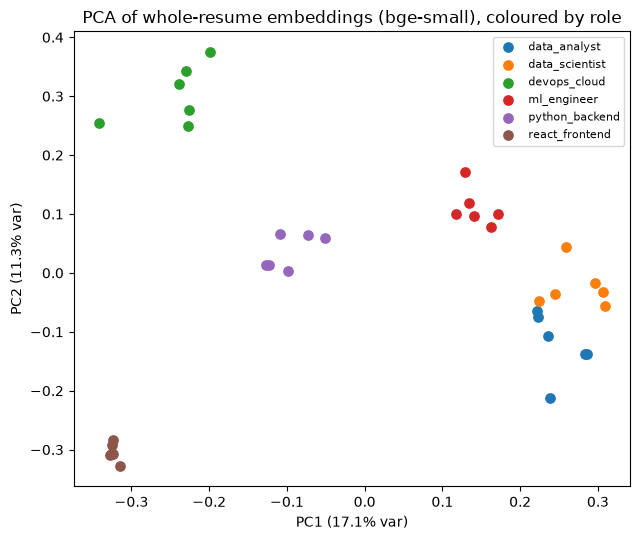

In [3]:
whole_stats = s.ingest(model="bge-small", chunking="whole", embedder=s.embedder)
whole_collection = s.client.get_collection(s.collection_name("bge-small", "whole"))
got = whole_collection.get(include=["embeddings", "metadatas"])
embeddings = np.array(got["embeddings"])
roles = [s.specs_by_id[m["candidate_id"]]["role"] for m in got["metadatas"]]

pca = PCA(n_components=2, random_state=0)
coords = pca.fit_transform(embeddings)

plt.figure(figsize=(6.5, 5.5))
for role in sorted(set(roles)):
    mask = [r == role for r in roles]
    plt.scatter(coords[mask, 0], coords[mask, 1], label=role, s=45)
plt.legend(fontsize=8)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var)")
plt.title("PCA of whole-resume embeddings (bge-small), coloured by role")
plt.tight_layout()
plt.show()

## Latency breakdown

The default pipeline's (bge-small/section/hybrid) ingest-time breakdown and
query-time breakdown (macro p50 across the 6 JDs). Re-ingests `section`
afterwards isn't needed here since this notebook never diverges from the
default collection after this point.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

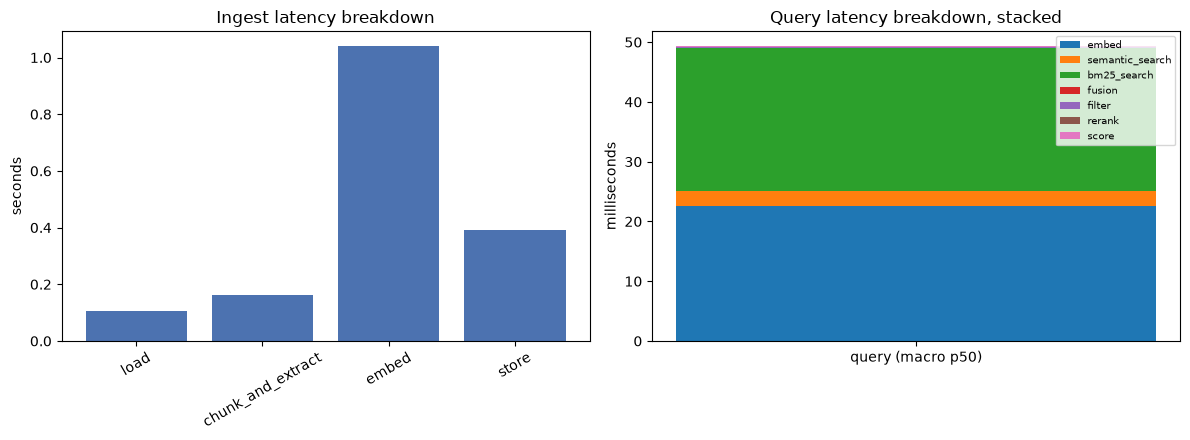

In [4]:
default_results = s.run_eval(model="bge-small", chunking="section", mode="hybrid", warm_runs=5)

ingest_times = default_results["latency"]["ingest"]["timings_s"]
stages_ingest = [stage for stage in ingest_times if stage != "total"]

query_p50 = default_results["latency"]["query"]["macro_avg"]
stages_query = [stage for stage in query_p50 if stage != "total"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(stages_ingest, [ingest_times[stage] for stage in stages_ingest], color="#4C72B0")
axes[0].set_title("Ingest latency breakdown")
axes[0].set_ylabel("seconds")
axes[0].tick_params(axis="x", rotation=30)

colors = plt.cm.tab10.colors
bottom = 0.0
for i, stage in enumerate(stages_query):
    value = query_p50[stage]["p50_ms"]
    axes[1].bar(["query (macro p50)"], [value], bottom=bottom, label=stage, color=colors[i % 10])
    bottom += value
axes[1].set_title("Query latency breakdown, stacked")
axes[1].set_ylabel("milliseconds")
axes[1].legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

In [5]:
# The latency cell's `run_eval` call just re-ingested "bge-small/section" (it
# deletes and recreates the collection every call), which invalidates `s.collection`
# and makes `s.candidates` a stale snapshot. Refresh both before using `s.score_all`/
# `s.ranking_for` again below; content is unchanged, only the collection handle is.
s.collection = s.client.get_collection(s.collection_name("bge-small", "section"))
s.candidates = s.load_candidates("bge-small", "section")
s.candidates_by_id = {c.candidate_id: c for c in s.candidates}

## Failure analysis

Specific misses (a relevant or highly-relevant candidate that doesn't make
the default pipeline's top 10) and false positives (a not-relevant
candidate that does), across all 6 JDs.


In [6]:
misses = []
false_positives = []
for jd_path in s.jd_paths:
    jd_id = s.jd_id_for_path(jd_path)
    jd = s.parse_jd(jd_path.read_text())
    grades = {filename: grade for filename, grade in s.ground_truth[jd_id].items()}
    ranking = s.ranking_for(jd)
    top10 = set(ranking[:10])
    scored = s.score_all(jd)
    for cid, grade in grades.items():
        if grade >= 1 and cid not in top10:
            misses.append(
                {"jd": jd_id, "candidate": cid, "grade": grade, "score": scored[cid].score}
            )
        if cid in top10 and grade == 0:
            false_positives.append({"jd": jd_id, "candidate": cid, "score": scored[cid].score})

misses_df = pd.DataFrame(misses).sort_values(["jd", "grade"], ascending=[True, False])
misses_df

,jd,candidate,grade,score
0,backend_python_fastapi,noah_nguyen.pdf,1,0
1,backend_python_fastapi,hiroshi_rivera.docx,1,0
2,backend_python_fastapi,omar_khan.txt,1,0
3,backend_python_fastapi,benjamin_cook.txt,1,20
4,backend_python_fastapi,nadia_baker.txt,1,0
5,backend_python_fastapi,luca_collins.txt,1,22
6,devops_kubernetes_aws,yuki_adams.pdf,1,19
7,devops_kubernetes_aws,owen_miller.docx,1,21
8,junior_data_analyst,oliver_taylor.pdf,1,36
9,junior_data_analyst,matthew_phillips.txt,1,37


In [7]:
pd.DataFrame(false_positives)

,jd,candidate,score
0,backend_python_fastapi,ella_garcia.pdf,43
1,backend_python_fastapi,dmitri_wilson.txt,48
2,backend_python_fastapi,scarlett_young.pdf,46
3,backend_python_fastapi,daniel_campbell.md,45
4,mlops_cross_role,sofia_lee.docx,55
5,mlops_cross_role,owen_miller.docx,48
6,react_frontend,priya_flores.pdf,14
7,react_frontend,sofia_lee.docx,16
8,react_frontend,olivia_thomas.pdf,14
9,react_frontend,benjamin_cook.txt,14


Causes behind these misses, from the deviations already recorded in
`PLAN.md`:

- **Date-range precision.** A bare-year date range (`"2022-2023"`) is parsed
  to its unbiased midpoint, and `"Present"` resolves against the real
  `date.today()`, which keeps drifting further from the dataset generator's
  fixed reference date. Step 3's own check found 2 of 36 candidates (94%)
  with `experience_years` off by more than a year for this reason — those
  candidates can fail a JD's total-years must-have, or score lower on
  required-skill-years must-haves, that the true spec says they should pass.
- **Skills named only in bullets, not on the Skills line.** `skill_years`
  fallback logic (Step 4's second deviation) credits a skill confirmed
  present but never found in a dated entry with the candidate's total
  `experience_years`; this is a deliberate approximation, not an exact
  per-skill duration, and can over- or under-credit a candidate relative to
  the true spec.
- **Synthetic hard negatives.** The dataset deliberately includes adjacent
  roles (analyst vs. data scientist, backend vs. DevOps) and "right skills,
  too junior" profiles. Some of the false positives above are exactly this:
  a candidate semantically and lexically close to the JD who the ground
  truth grades 0 only on role fit or seniority, not skill overlap — which is
  precisely what the must-have filter and `required_coverage` term are for,
  and why `filter_accuracy`, not retrieval accuracy, is the metric that
  should catch them.

**Conclusions.** Across the seven notebooks: hybrid retrieval meets or
beats semantic-only on macro nDCG@10
([03](03_experiment_b_search_mode.ipynb)), confirming Step 5's own
verification — though keyword-only edges out hybrid by a hair on this
small, keyword-heavy dataset, a gap that should favour hybrid more on
paraphrased text. `section` chunking is at least as strong as `fixed` or
`whole` ([02](02_experiment_a_chunking_strategy.ipynb)). The heavier
`qwen3-0.6b` model buys some accuracy over `bge-small` at several times the
latency ([04](04_experiment_c_embedding_model.ipynb)), making `bge-small`
the better default at this scale. The configured score weights sit in a
broad optimum rather than a sharp one, and RRF k only matters with rerank
on ([05](05_experiment_d_weights_and_rrf.ipynb)). Reranking's own effect is
small, since the hybrid first-stage pool is already strong
([06](06_experiment_e_rerank.ipynb)).

**Threats to validity.**

- **The labels are synthetic.** `ground_truth.json`'s graded relevance and
  `resume_specs.json`'s true skills/years/degree come from the same
  generator that wrote the resumes, then were checked by hand — they are
  not independent, real-world labels, and risk circularity: a metric can
  look strong partly because the "true" values were easy for the generator
  to encode consistently, not because the pipeline would generalize to real
  resumes with messier phrasing.
- **Small N.** 36 resumes and 6 JDs means every metric here is sensitive to
  a handful of candidates; a single miss changes macro nDCG@10 by a
  noticeable amount. The per-JD tables in each experiment notebook matter
  more than any single macro-average headline number.
- **Growing date drift.** As noted above, `"Present"` resolves against the
  real `date.today()`, which keeps moving further from the dataset
  generator's fixed reference date. Extraction and filter accuracy will
  keep drifting downward over time for this reason alone, independent of
  any code change.
- **Hand-checked, not cross-validated, ground truth.** The graded relevance
  labels were reviewed by one person (the dataset's author) rather than by
  multiple independent raters, so there's no inter-rater agreement measure
  for how much the grades themselves could reasonably vary.
